# Task 4.12 — Overlap sweep



In [1]:
import numpy as np
import pennylane as qml
import matplotlib.pyplot as plt
from functools import reduce, lru_cache

np.random.seed(0)

PSI_OFFSET = np.pi / 2
NOISE_TYPES = ["depolarizing", "dephasing"]
S_VALUES = [2, 3, 4]


def delta_from_c(c):
    return 2 * np.arccos(np.sqrt(c))

## 2. Optimal measurement (collective $J$ projectors) and Swap Test

In [2]:
I2 = np.eye(2, dtype=complex)
PAULIS = [np.array([[0, 1], [1, 0]], dtype=complex),
          np.array([[0, -1j], [1j, 0]], dtype=complex),
          np.array([[1, 0], [0, -1]], dtype=complex)]

_proj_cache = {}


def J_projectors(S):
    """Projectors onto the eigenspaces of the total angular momentum J^2 of the 2S qubits."""
    if S in _proj_cache:
        return _proj_cache[S]
    n = 2 * S
    dim = 2 ** n
    Jops = [np.zeros((dim, dim), dtype=complex) for _ in range(3)]
    for i in range(n):
        for a, P in enumerate(PAULIS):
            ops = [I2] * n
            ops[i] = P / 2
            Jops[a] += reduce(np.kron, ops)
    J2 = sum(J @ J for J in Jops)
    w, V = np.linalg.eigh(J2)
    J = np.round(2 * (-1 + np.sqrt(1 + 4 * np.clip(w.real, 0, None))) / 2) / 2
    _proj_cache[S] = {Jv: V[:, J == Jv] for Jv in np.unique(J)}  # orthonormal basis of each J-subspace
    return _proj_cache[S]


def noisy_density_matrix(delta, S, p, noise_type):
    n = 2 * S
    dev = qml.device("default.mixed", wires=n)

    @qml.qnode(dev)
    def circuit():
        for i in range(S):
            qml.RY(PSI_OFFSET, wires=i)
        for i in range(S, n):
            qml.RY(PSI_OFFSET + delta, wires=i)
        if p > 0:
            for i in range(n):
                if noise_type == "depolarizing":
                    qml.DepolarizingChannel(p, wires=i)
                else:
                    qml.PhaseFlip(p, wires=i)
        return qml.density_matrix(wires=list(range(n)))

    return circuit()


def J_distribution(c, S, p, noise_type):
    rho = noisy_density_matrix(delta_from_c(c), S, p, noise_type)
    return {Jv: float(np.real(np.trace(Vs.conj().T @ rho @ Vs))) for Jv, Vs in J_projectors(S).items()}


def optimal_mse(c, S, p, noise_type):
    n = 2 * S
    return float(sum(pj * ((2 * Jv / n) ** 2 - c) ** 2 for Jv, pj in J_distribution(c, S, p, noise_type).items()))


dev_swap = qml.device("default.mixed", wires=3)


@qml.qnode(dev_swap)
def swap_test_circuit(delta, p_noise, noise_type):
    qml.RY(PSI_OFFSET, wires=2)
    qml.RY(PSI_OFFSET + delta, wires=1)
    if p_noise > 0:
        for w in (1, 2):
            if noise_type == "depolarizing":
                qml.DepolarizingChannel(p_noise, wires=w)
            else:
                qml.PhaseFlip(p_noise, wires=w)
    qml.Hadamard(wires=0)
    qml.CSWAP(wires=[0, 1, 2])
    qml.Hadamard(wires=0)
    return qml.probs(wires=0)


@lru_cache(maxsize=None)
def swap_p0(c, p, noise_type):
    return float(swap_test_circuit(delta_from_c(c), p, noise_type)[0])


def swap_mse(c, S, p, noise_type):
    p0 = swap_p0(c, p, noise_type)
    return float((2 * p0 - 1 - c) ** 2 + 4 * p0 * (1 - p0) / S)

## 3. Sweep: $c\in[0.1,0.9]$ and $p\in[0,0.5]$ for $S=2,3,4$, both noise channels

In [3]:
c_grid = np.round(np.linspace(0.1, 0.9, 9), 2)
p_grid = np.linspace(0.0, 0.5, 21)

mse_swap = {nt: {} for nt in NOISE_TYPES}
mse_opt = {nt: {} for nt in NOISE_TYPES}

for S in S_VALUES:
    for nt in NOISE_TYPES:
        ms = np.zeros((len(c_grid), len(p_grid)))
        mo = np.zeros((len(c_grid), len(p_grid)))
        for ic, c in enumerate(c_grid):
            for ip, p in enumerate(p_grid):
                ms[ic, ip] = swap_mse(float(c), S, float(p), nt)
                mo[ic, ip] = optimal_mse(float(c), S, float(p), nt)
        mse_swap[nt][S], mse_opt[nt][S] = ms, mo
    print(f"S={S}: done ({len(c_grid)} overlaps x {len(p_grid)} noise levels x {len(NOISE_TYPES)} channels)")


def gap(nt, S):
    return mse_swap[nt][S] / mse_opt[nt][S]

S=2: done (9 overlaps x 21 noise levels x 2 channels)


S=3: done (9 overlaps x 21 noise levels x 2 channels)


S=4: done (9 overlaps x 21 noise levels x 2 channels)


## 4. Plots

### 4.1 Noiseless case: advantage vs. overlap

Dashed line: asymptotic ratio $(1+c)/(2c)$ predicted by the paper for $M=N\to\infty$.

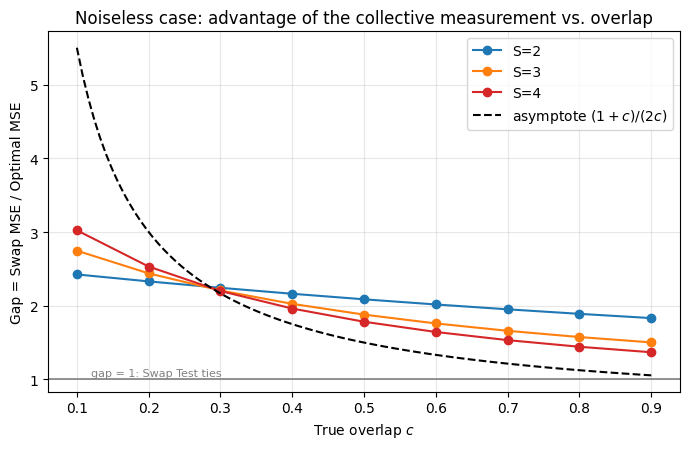

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.6))
colors = {2: "tab:blue", 3: "tab:orange", 4: "tab:red"}
for S in S_VALUES:
    ax.plot(c_grid, gap("depolarizing", S)[:, 0], "o-", color=colors[S], label=f"S={S}")
c_dense = np.linspace(0.1, 0.9, 100)
ax.plot(c_dense, (1 + c_dense) / (2 * c_dense), "k--", label=r"asymptote $(1+c)/(2c)$")
ax.axhline(1.0, color="gray", lw=1.2)
ax.text(0.12, 1.04, "gap = 1: Swap Test ties", color="gray", fontsize=8)
ax.set_xlabel("True overlap $c$")
ax.set_ylabel("Gap = Swap MSE / Optimal MSE")
ax.set_title("Noiseless case: advantage of the collective measurement vs. overlap")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("gap_vs_overlap_noiseless.png", dpi=150)
plt.show()

### 4.2 With noise: gap vs. overlap for several noise levels

Each curve is one noise level $p$. **Any curve dipping to or below the horizontal line (gap = 1) marks overlaps where the Swap Test matches or beats the collective measurement.**

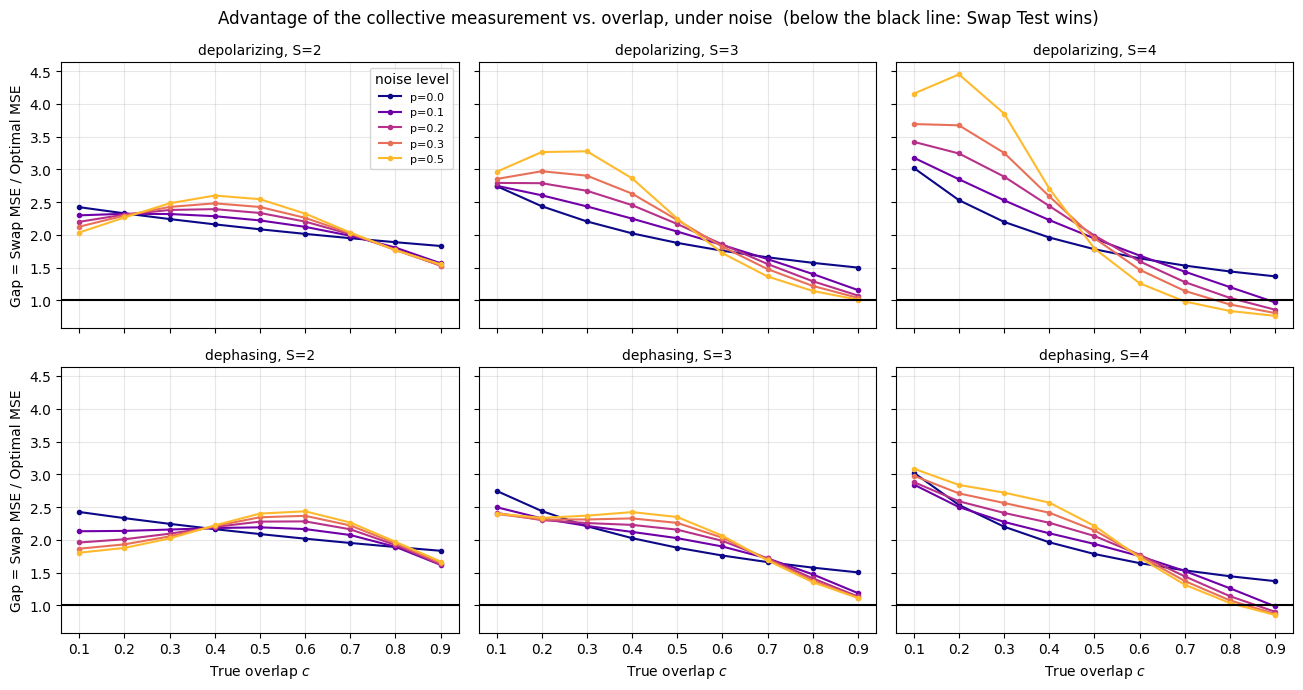

In [5]:
p_show = [0.0, 0.1, 0.2, 0.3, 0.5]
cmap = plt.get_cmap("plasma")
fig, axes = plt.subplots(len(NOISE_TYPES), len(S_VALUES), figsize=(13, 7), sharex=True, sharey=True)
for r, nt in enumerate(NOISE_TYPES):
    for k, S in enumerate(S_VALUES):
        ax = axes[r, k]
        for j, p_sel in enumerate(p_show):
            ip = int(np.argmin(np.abs(p_grid - p_sel)))
            ax.plot(c_grid, gap(nt, S)[:, ip], "o-", ms=3, color=cmap(j / (len(p_show) - 1) * 0.85), label=f"p={p_sel}")
        ax.axhline(1.0, color="black", lw=1.5)
        ax.set_title(f"{nt}, S={S}", fontsize=10)
        ax.grid(alpha=0.3)
        if r == len(NOISE_TYPES) - 1:
            ax.set_xlabel("True overlap $c$")
        if k == 0:
            ax.set_ylabel("Gap = Swap MSE / Optimal MSE")
axes[0, 0].legend(fontsize=8, title="noise level")
fig.suptitle("Advantage of the collective measurement vs. overlap, under noise  (below the black line: Swap Test wins)")
plt.tight_layout()
plt.savefig("gap_vs_overlap_noisy.png", dpi=150)
plt.show()

## 5. Does the Swap Test match or beat the collective measurement for some $c$?

In [6]:
print(f"{'noise':<14}{'S':<4}{'#pts gap<=1':<13}{'of':<5}{'overlaps c':<22}{'min p':<8}{'best gap'}")
for nt in NOISE_TYPES:
    for S in S_VALUES:
        g = gap(nt, S)
        mask = g <= 1.0
        n_cr = int(mask.sum())
        if n_cr:
            ic, ip = np.where(mask)
            cs = sorted(set(float(x) for x in c_grid[ic]))
            print(f"{nt:<14}{S:<4}{n_cr:<13}{g.size:<5}{str(cs):<22}{p_grid[ip].min():<8.3f}{g.min():.3f}x")
        else:
            print(f"{nt:<14}{S:<4}{0:<13}{g.size:<5}{'none':<22}{'-':<8}{g.min():.3f}x")


def crossing_threshold(gap_row):
    idx = np.where(gap_row <= 1.0)[0]
    if len(idx) == 0:
        return np.nan
    j = idx[0]
    if j == 0:
        return float(p_grid[0])
    g0, g1 = gap_row[j - 1], gap_row[j]
    return float(p_grid[j - 1] + (1 - g0) / (g1 - g0) * (p_grid[j] - p_grid[j - 1]))


print()
print("Smallest noise level p* at which the Swap Test matches/beats the collective measurement (nan = never for p <= 0.5)")
print(f"{'noise':<14}{'S':<4}" + "".join(f"c={c:<7}" for c in c_grid))
for nt in NOISE_TYPES:
    for S in S_VALUES:
        print(f"{nt:<14}{S:<4}" + "".join(f"{crossing_threshold(gap(nt, S)[i, :]):<9.3f}" for i in range(len(c_grid))))

noise         S   #pts gap<=1  of   overlaps c            min p   best gap
depolarizing  2   0            189  none                  -       1.531x
depolarizing  3   0            189  none                  -       1.013x
depolarizing  4   30           189  [0.7, 0.8, 0.9]       0.100   0.766x
dephasing     2   0            189  none                  -       1.614x
dephasing     3   0            189  none                  -       1.111x
dephasing     4   17           189  [0.9]                 0.100   0.852x

Smallest noise level p* at which the Swap Test matches/beats the collective measurement (nan = never for p <= 0.5)
noise         S   c=0.1    c=0.2    c=0.3    c=0.4    c=0.5    c=0.6    c=0.7    c=0.8    c=0.9    
depolarizing  2   nan      nan      nan      nan      nan      nan      nan      nan      nan      
depolarizing  3   nan      nan      nan      nan      nan      nan      nan      nan      nan      
depolarizing  4   nan      nan      nan      nan      nan      nan     

## 6.bias / variance check

The MSE above uses estimators calibrated for the **noiseless** case. Under noise they become biased, and $\text{MSE}=\text{bias}^2+\text{variance}$. The table decomposes the MSE at representative points to see what drives the crossing.

In [7]:
def opt_bias_var(c, S, p, noise_type):
    n = 2 * S
    probs = J_distribution(c, S, p, noise_type)
    mean = sum(pj * (2 * Jv / n) ** 2 for Jv, pj in probs.items())
    var = sum(pj * (2 * Jv / n) ** 4 for Jv, pj in probs.items()) - mean ** 2
    return (mean - c) ** 2, var


def swap_bias_var(c, S, p, noise_type):
    p0 = swap_p0(c, p, noise_type)
    return (2 * p0 - 1 - c) ** 2, 4 * p0 * (1 - p0) / S


print(f"{'noise':<14}{'c':<5}{'p':<5}{'S':<3}| {'Swap bias^2':<12}{'Swap var':<10}| {'Opt bias^2':<12}{'Opt var':<10}| gap")
for nt in NOISE_TYPES:
    for c, p in [(0.9, 0.0), (0.9, 0.1), (0.9, 0.3), (0.7, 0.3), (0.2, 0.3)]:
        S = 4
        sb, sv = swap_bias_var(c, S, p, nt)
        ob, ov = opt_bias_var(c, S, p, nt)
        print(f"{nt:<14}{c:<5}{p:<5}{S:<3}| {sb:<12.4f}{sv:<10.4f}| {ob:<12.4f}{ov:<10.4f}| {(sb + sv) / (ob + ov):.3f}")

noise         c    p    S  | Swap bias^2 Swap var  | Opt bias^2  Opt var   | gap
depolarizing  0.9  0.0  4  | 0.0000      0.0475    | 0.0002      0.0345    | 1.369


depolarizing  0.9  0.1  4  | 0.0099      0.0898    | 0.0237      0.0790    | 0.972


depolarizing  0.9  0.3  4  | 0.0655      0.1463    | 0.1684      0.0937    | 0.808


depolarizing  0.7  0.3  4  | 0.0164      0.1682    | 0.0729      0.0881    | 1.146


depolarizing  0.2  0.3  4  | 0.0369      0.2116    | 0.0069      0.0607    | 3.674
dephasing     0.9  0.0  4  | 0.0000      0.0475    | 0.0002      0.0345    | 1.369


dephasing     0.9  0.1  4  | 0.0207      0.1071    | 0.0427      0.0872    | 0.984
dephasing     0.9  0.3  4  | 0.1129      0.1705    | 0.2420      0.0842    | 0.869


dephasing     0.7  0.3  4  | 0.0282      0.1792    | 0.0657      0.0856    | 1.371
dephasing     0.2  0.3  4  | 0.0635      0.1989    | 0.0232      0.0737    | 2.708


## 7. Conclusion

### Does the advantage of the collective measurement depend on the overlap $c$?

**Yes,** in the noiseless case the gap (Swap MSE / Optimal MSE) goes from $2.42,\\,2.75,\\,3.02$ at $c=0.1$ to $1.83,\\,1.50,\\,1.37$ at $c=0.9$ (for $S=2,3,4$), following the paper's asymptotic ratio $(1+c)/(2c)$, which goes from $5.5$ to $1.056$. The advantage is largest at small overlaps and thins out as $c\\to1$. Its trend with $S$ also depends on $c$: it **grows** with $S$ for $c\\le0.2$ (e.g. $c=0.2$: $2.33\\to2.44\\to2.53$, the numbers quoted in Sprint 3), stays flat around $c\\approx0.3$ ($\\approx2.2$), and **shrinks** with $S$ for $c\\ge0.4$ (e.g. $c=0.9$: $1.83\\to1.50\\to1.37$), always above 1.

### Is there any $c$ for which the Swap Test matches or beats the collective measurement?

**Yes, but only for $S=4$, only with noise, and only at high overlap.**

| Case | Result |
|---|---|
| Noiseless ($p=0$), any $c\\in[0.1,0.9]$, $S=2,3,4$ | **No.** Gap $>1.37$ everywhere. |
| $S=2$, any $c$, any $p\\le0.5$, both channels | **No.** Best gap $1.53$ (depolarizing) / $1.61$ (dephasing). |
| $S=3$, any $c$, any $p\\le0.5$, both channels | **No**, but close: best gap $1.013$ (depolarizing) / $1.111$ (dephasing), at $c=0.9$ and large $p$. |
| $S=4$, depolarizing | **Yes**, for $c=0.7,0.8,0.9$. Noise needed: $p^*\\approx0.47,\\,0.23,\\,0.086$. Best gap $0.766$ at $c=0.9$, $p=0.5$ (Swap Test MSE $23\\%$ lower). |
| $S=4$, dephasing | **Yes**, only at $c=0.9$ ($p^*\\approx0.09$). Best gap $0.852$. |
| Any $S\\le4$, $c\\le0.6$ | **No**, at any noise level up to $p=0.5$. |

So the statement "$S=2,3,4$ do not cross" is true for $S=2,3$ and for $c\\le0.6$, but **not** for $S=4$ at high overlap under noise.